# CA3

### Imports

Import all necessary packages.

In [331]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


### Reading data

Construct a relative file path, read a CSV file into a DataFrame, and print the first 5 rows.

In [332]:
current_folder = Path.cwd()
all_train_data_path = current_folder / "data" / "train.csv"
final_test_data_path = current_folder / "data" / "test.csv"

df = pd.read_csv(all_train_data_path, index_col="Id")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Id,,,,,,,,,,,,
13,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0
705,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0
1408,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1
144,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1
557,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0


### Data exploration and visualisation

Display each column's data type and counts of unique and missing values.

In [333]:
stats = pd.DataFrame({
    "Data type": df.dtypes, 
    "Unique values": df.nunique(),
    "Missing values": df.isna().sum()
    })

stats.index.name = "Column name"

stats

,Data type,Unique values,Missing values
Column name,,,
fixed acidity,float64,83,0
volatile acidity,float64,125,0
citric acid,float64,76,0
residual sugar,float64,72,0
chlorides,float64,121,0
free sulfur dioxide,float64,51,0
total sulfur dioxide,float64,128,0
density,float64,331,0
pH,float64,85,0


**Observations**
* The dataset contains no missing values.
* All features are numerical.
* The target variable is binary.

In [334]:
target = df["quality"]
df = df.drop(columns=["quality"])

Visualize the distributions of features using histograms and box plots.

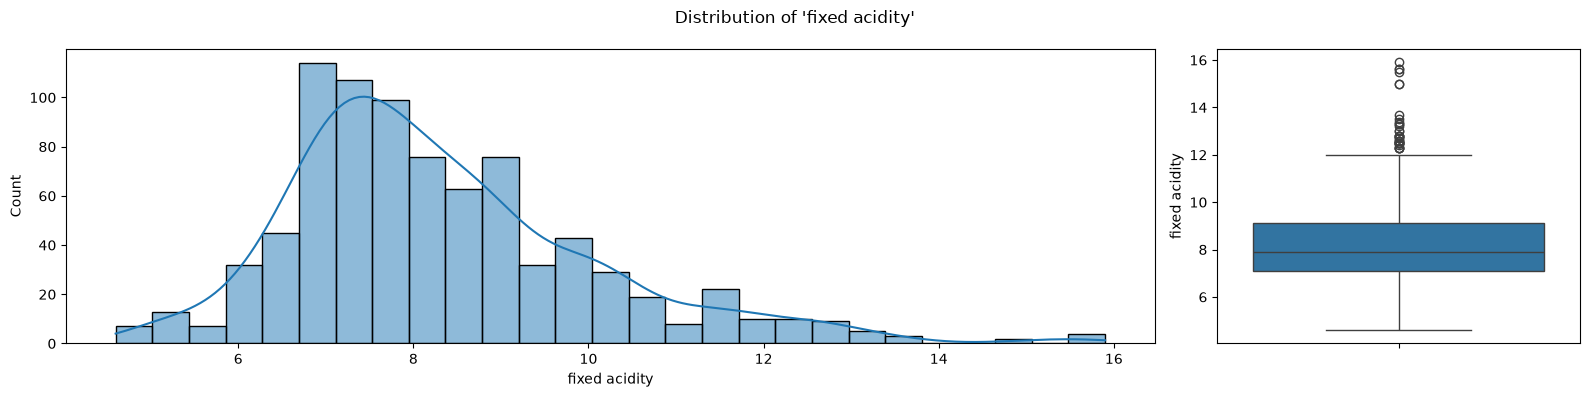

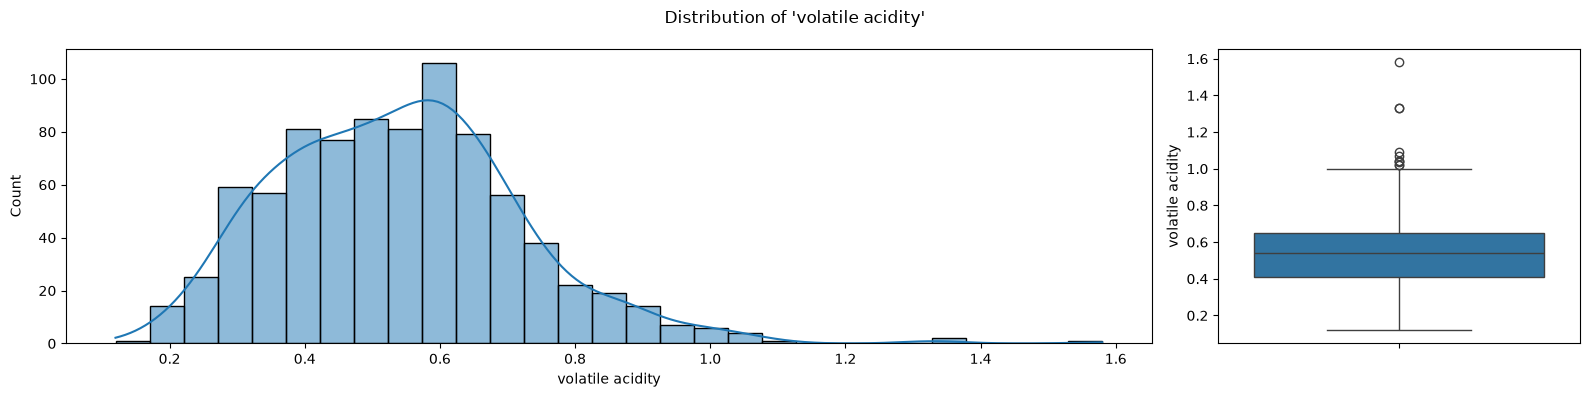

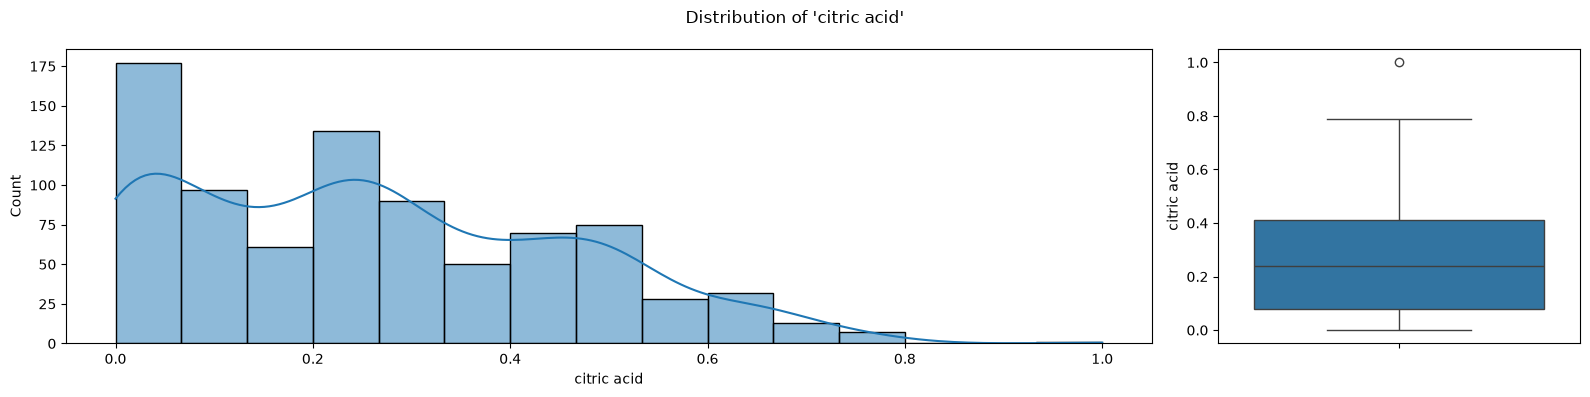

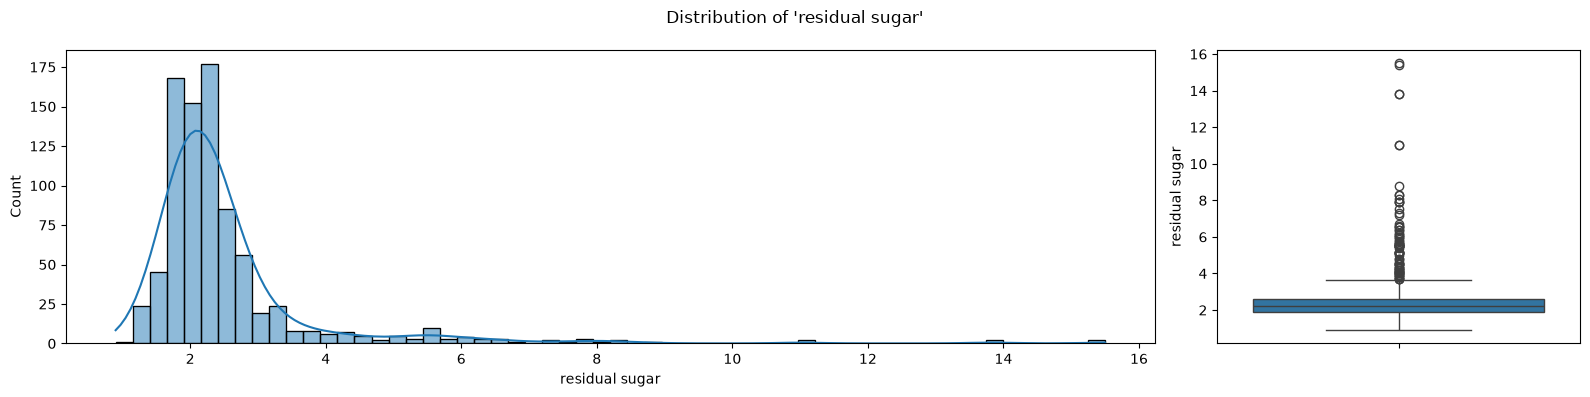

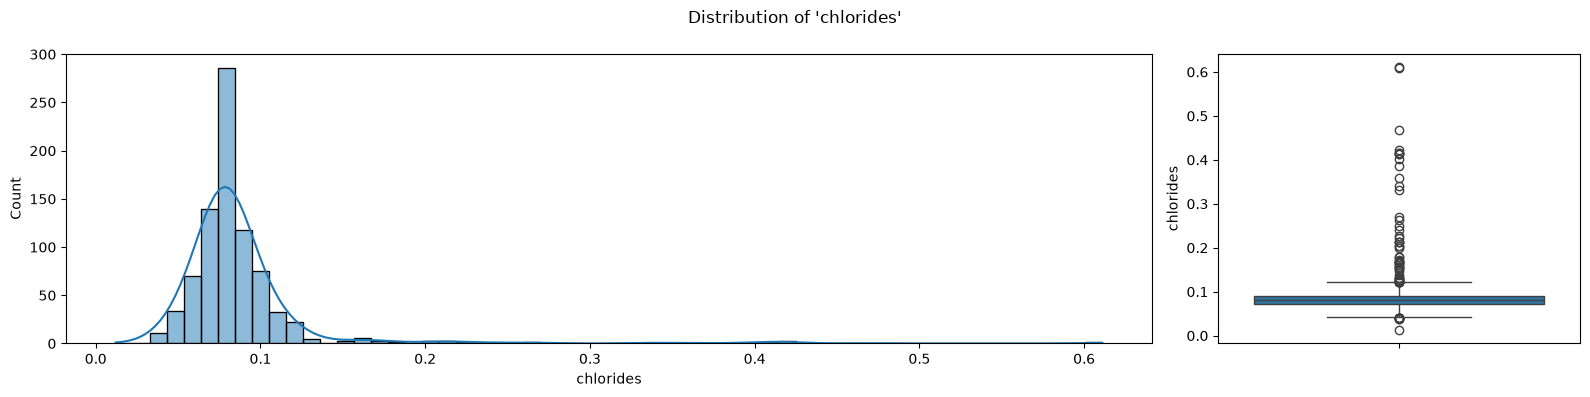

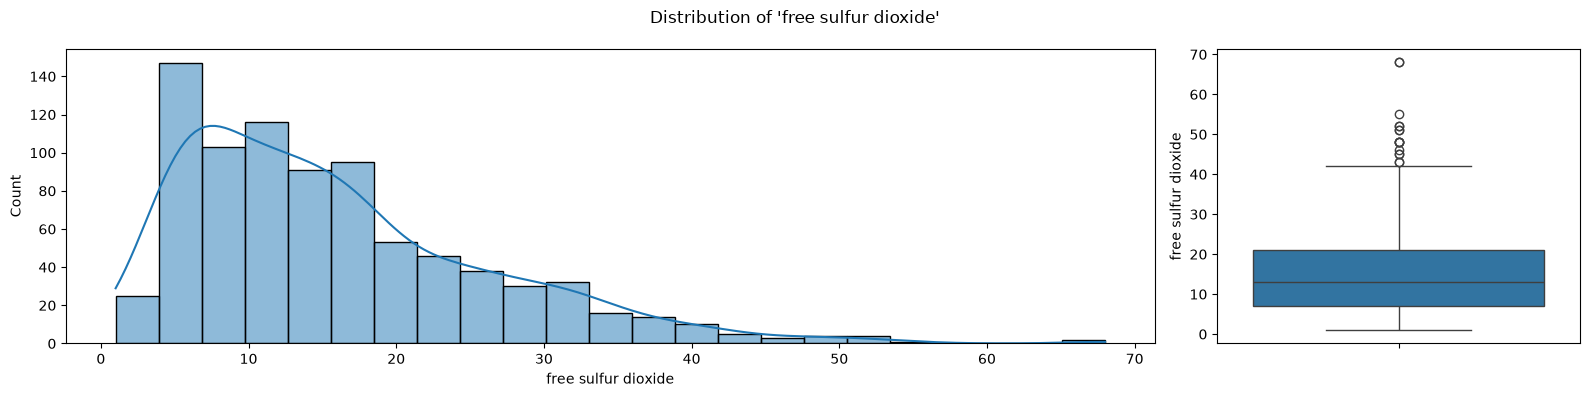

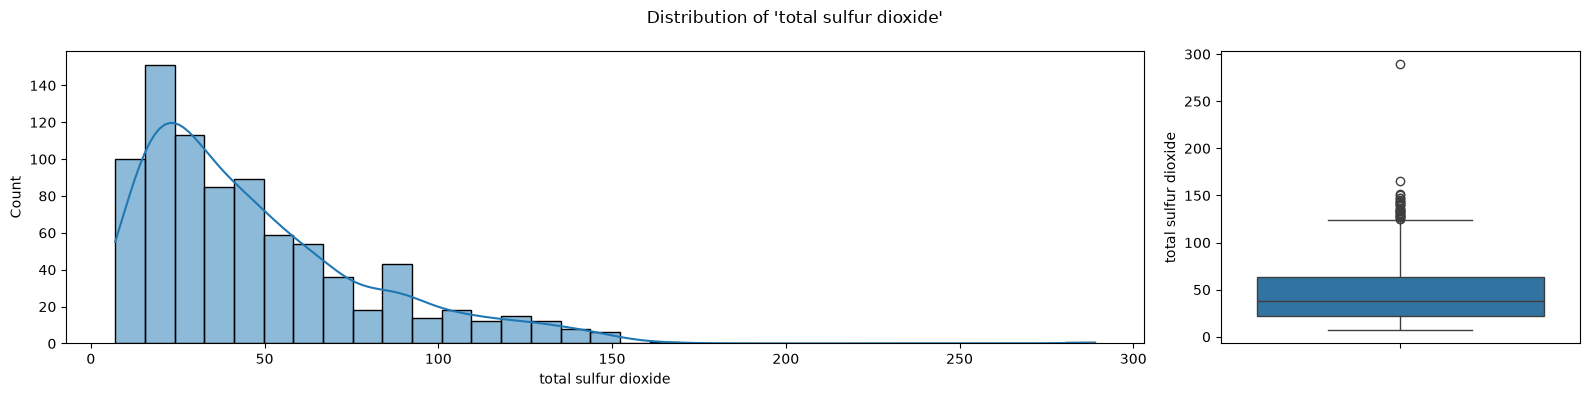

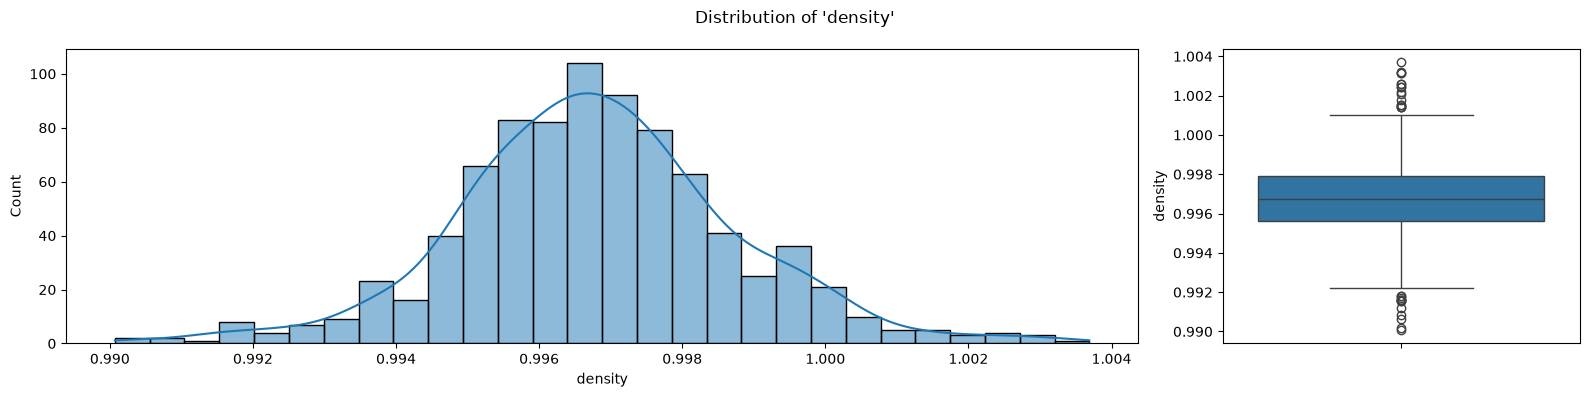

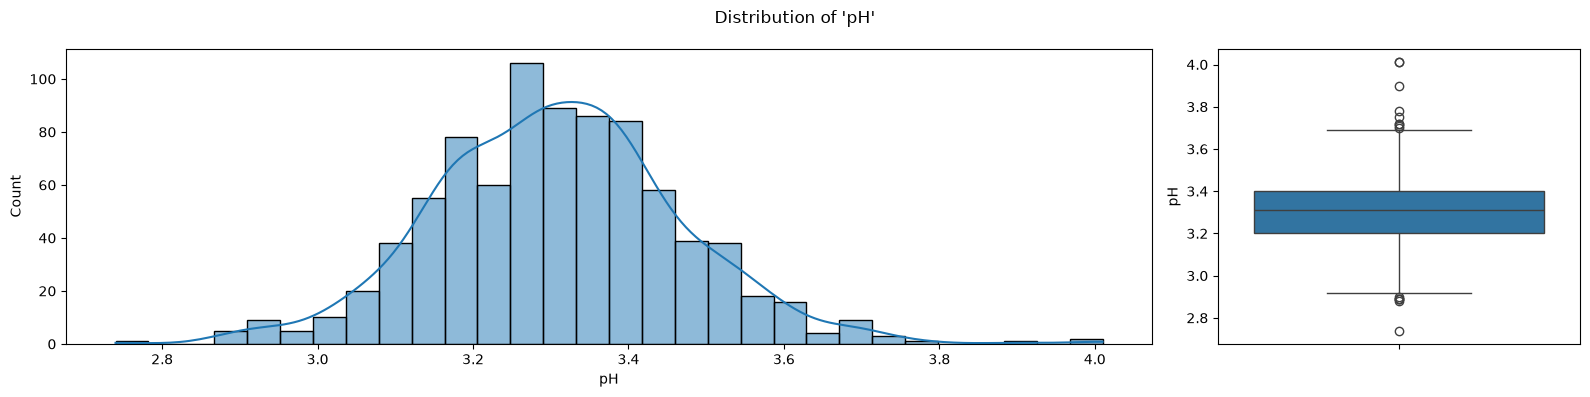

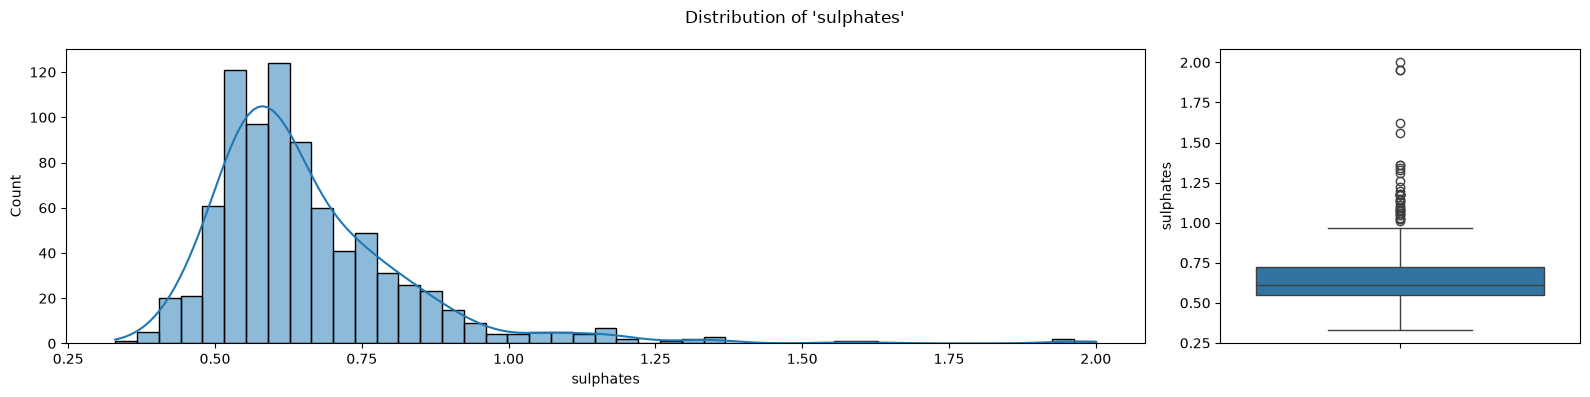

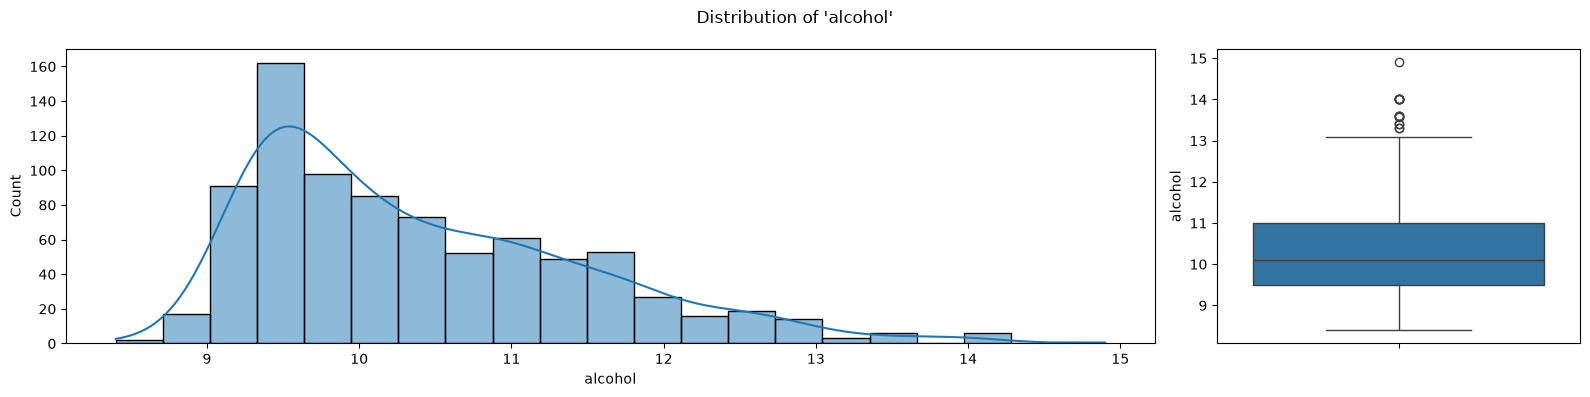

In [335]:
for i, feature in enumerate(df.columns):
    fig, axes = plt.subplots(
        1, 2, 
        figsize=(16, 4), 
        gridspec_kw={'width_ratios': [3, 1]} # histplots need more space than boxlots
        )

    sns.histplot(
        data=df[feature],
        ax=axes[0], 
        kde=True  # add a smooth line
    )

    sns.boxplot(data=df[feature], ax=axes[1])
    
    fig.suptitle(f"Distribution of '{feature}'")
    fig.tight_layout()


plt.show()

The box plots suggest that the features contain numerous outliers. Let's identify these outliers using the interqurtile range (IQR) method.

In [336]:
q1 = df.quantile(0.25)
q3 = df.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (df < lower_bound) |
    (df > upper_bound)
)

outlier_mask.sum(axis=0)


Column name
fixed acidity           33
volatile acidity        10
citric acid              1
residual sugar          76
chlorides               63
free sulfur dioxide     16
total sulfur dioxide    30
density                 29
pH                      15
sulphates               38
alcohol                 15
dtype: int64

### Data cleaning

We have too many potential outliers to remove them all without significantly reducing the size of our dataset. Let's skip data cleaning for now.

### Data preprocessing and visualisation

Let's add new features.

In [337]:
def add_features(df):
    new_df = df.copy()

    #new_df["molecular sulfur dioxide"] = (df["free sulfur dioxide"] / (1 + 10 ** (df["pH"] - 1.81)))

    #new_df["bound sulfur dioxide"] = (df["total sulfur dioxide"] - df["free sulfur dioxide"])

    #new_df["fraction sulfur dioxide"] = (df["free sulfur dioxide"] / df["total sulfur dioxide"])

    #new_df["acidity ratio"] = (df["fixed acidity"] / df["volatile acidity"])

    #new_df["alcohol to sugar"] = (df["alcohol"] / df["residual sugar"])
    
    #new_df["alcohol-density"] = (df["alcohol"] * df["density"])

    #new_df["pH-acidity"] = (df["pH"] * df["fixed acidity"])

    #new_df["sugar to facidity"] = (df["residual sugar"] / df["fixed acidity"] ) 

    #new_df["sugar to vacidity"] = (df["residual sugar"] / df["volatile acidity"] )    
    
    return new_df

In [ ]:
def add_features(df):
    new_df = df.copy()

    new_df["volatile_2"] = df["volatile acidity"] ** 2
    
    new_df["free_2"] = df["free sulfur dioxide"] ** 2
    
    new_df["fraction sulfur dioxide"] = (df["free sulfur dioxide"] / df["total sulfur dioxide"])

    new_df["bound sulfur dioxide"] = (df["total sulfur dioxide"] - df["free sulfur dioxide"])
    
    return new_df.drop(columns=["pH", "residual sugar", "density"])

In [339]:
df = add_features(df)

In [340]:
#fig, ax = plt.subplots(3, 1, figsize=(6, 18))

#sns.violinplot(df["molecular sulfur dioxide"], ax=ax[0])
#sns.violinplot(df["bound sulfur dioxide"], ax=ax[1])
#sns.violinplot(df["fraction sulfur dioxide"], ax=ax[2])

In [341]:
log_features = [
    "chlorides", 
    "free sulfur dioxide", 
    "total sulfur dioxide",
    "bound sulfur dioxide",
    "sulphates",
]

df[log_features] = df[log_features].apply(np.log)

### Modelling

In [342]:
X = df
y = target

n_iter = 60

# Set ranges for C and gamma
range_C = np.logspace(-1, 1, 30)
range_gamma = np.logspace(-2, 0, 30)

acc_train_range = np.zeros((len(range_C), len(range_gamma))) 
acc_test_range = np.zeros((len(range_C), len(range_gamma)))

for C_ind, C_val in enumerate(range_C):
    for gamma_ind, gamma in enumerate(range_gamma):

        accuracy_train = np.zeros(n_iter)
        accuracy_test = np.zeros(n_iter)

        for rs in range(n_iter):

            # Split into train and test
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=0.3, random_state=rs, stratify=y)

            # Scale
            sc = StandardScaler().fit(X_train)
            X_train = sc.transform(X_train)
            X_test = sc.transform(X_test)

            # Train
            clf = svm.SVC(
                kernel="rbf",
                C=C_val,
                gamma=gamma,
                random_state=42
            ).fit(X_train, y_train)

            # Calculate accuracy
            accuracy_train[rs] = clf.score(X_train, y_train)
            accuracy_test[rs] = clf.score(X_test, y_test)

        acc_train_range[C_ind, gamma_ind] = accuracy_train.mean()
        acc_test_range[C_ind, gamma_ind] = accuracy_test.mean()

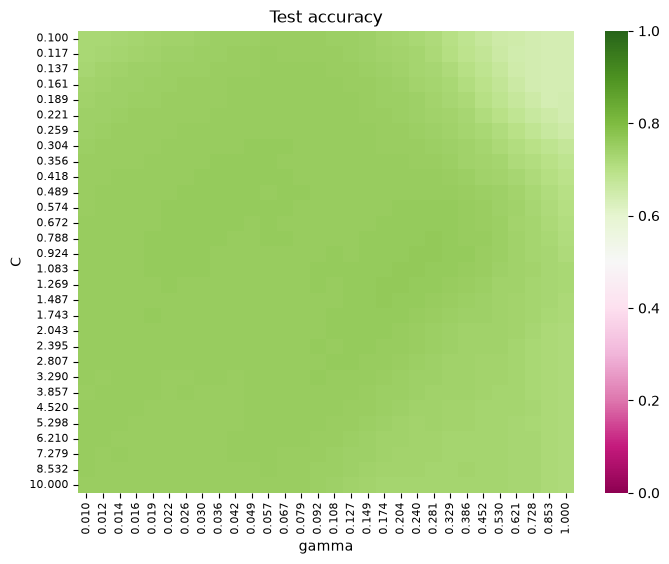

In [343]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    data=acc_test_range,
    yticklabels=[f"{c:.3f}" for c in range_C],
    xticklabels=[f"{c:.3f}" for c in range_gamma],
    annot=False,
    cmap="PiYG",
    vmin=0,
    vmax=1
)

plt.title("Test accuracy")
plt.ylabel("C")
plt.xlabel("gamma")

plt.tick_params(axis="x", labelsize=8)
plt.tick_params(axis="y", labelsize=8)


plt.show()

In [344]:
best_idx = np.unravel_index(
    np.argmax(acc_test_range),
    acc_test_range.shape,
)

best_C = range_C[best_idx[0]]
best_gamma = range_gamma[best_idx[1]]

print(f"Best average accuracy: {acc_test_range.max():.5f}")
print(f"Parameter C: {best_C:.5f}")
print(f"Parameter gamma: {best_gamma:.5f}")


Best average accuracy: 0.76301
Parameter C: 0.92367
Parameter gamma: 0.23950


In [345]:
"""
Best average accuracy: 0.76335
Parameter C: 1.27427
Parameter gamma: 0.14384
"""
None

### Final evaluation

In [348]:
X_train = X
y_train = y

X_test = pd.read_csv(final_test_data_path, index_col="Id")

X_test = add_features(X_test)

X_test[log_features] = X_test[log_features].apply(np.log)

sc = StandardScaler().fit(X_train)
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

clf = svm.SVC(
    kernel="rbf",
    C=best_C,
    gamma=best_gamma,
    random_state=42
).fit(X_train, y_train)

### Kaggle submission

In [349]:
y_test = clf.predict(X_test)
y_test = pd.DataFrame(y_test, columns=["quality"])
y_test.index.name = "Id"

predictions_path = current_folder / "data" / "SVM.csv"

y_test.to_csv(predictions_path, index=True)